Missing Values

In [62]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer

df_missing = pd.DataFrame({
    'Umur': [25, 30, np.nan, 35],
    'Gaji': [50000, 60000, 55000, np.nan],
    'Kota': ['Jakarta', 'Bandung', np.nan, 'Jakarta']
})

print("DataFrame sebelum imputasi:")
print(df_missing)

imputer_num = SimpleImputer(strategy='mean')
df_missing['Umur'] = imputer_num.fit_transform(df_missing[['Umur']])

imputer_median = SimpleImputer(strategy='median')
df_missing['Gaji'] = imputer_median.fit_transform(df_missing[['Gaji']])

imputer_cat = SimpleImputer(strategy='most_frequent')
df_missing['Kota'] = imputer_cat.fit_transform(df_missing[['Kota']].values.reshape(-1, 1)).ravel()

print("DataFrame setelah imputasi:")
print(df_missing)

DataFrame sebelum imputasi:
   Umur     Gaji     Kota
0  25.0  50000.0  Jakarta
1  30.0  60000.0  Bandung
2   NaN  55000.0      NaN
3  35.0      NaN  Jakarta
DataFrame setelah imputasi:
   Umur     Gaji     Kota
0  25.0  50000.0  Jakarta
1  30.0  60000.0  Bandung
2  30.0  55000.0  Jakarta
3  35.0  55000.0  Jakarta


Encoding

In [19]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

df = pd.DataFrame({
    'Nama': ['Andi', 'Budi', 'Cici', 'Dedi'],
    'Nilai': ['A', 'B', 'C', 'A']
})

le = LabelEncoder()
df['Nilai_Encoded'] = le.fit_transform(df['Nilai']) 

df_onehot = pd.get_dummies(df, columns=['Nilai'], prefix='Nilai')

print("DataFrame dengan Label Encoding:")
print(df)
print("DataFrame dengan One-Hot Encoding:")
print(df_onehot)

DataFrame dengan Label Encoding:
   Nama Nilai  Nilai_Encoded
0  Andi     A              0
1  Budi     B              1
2  Cici     C              2
3  Dedi     A              0
DataFrame dengan One-Hot Encoding:
   Nama  Nilai_Encoded  Nilai_A  Nilai_B  Nilai_C
0  Andi              0     True    False    False
1  Budi              1    False     True    False
2  Cici              2    False    False     True
3  Dedi              0     True    False    False


Feature Scaling

In [68]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler

df = pd.DataFrame({
    'Umur': [25, 30, 20, 35],
    'Gaji': [2000, 1000, 10000, 5000],
})

umur = df[['Umur']]
gaji = df[['Gaji']]

scaler_minmax = MinMaxScaler()
X_norm = scaler_minmax.fit_transform(umur)

print("Data setelah Min-Max Scaling:")
print(X_norm)

scaler_std = StandardScaler()
X_std = scaler_std.fit_transform(gaji)

print("Data setelah Standard Scaling:")
print(X_std)

Data setelah Min-Max Scaling:
[[0.33333333]
 [0.66666667]
 [0.        ]
 [1.        ]]
Data setelah Standard Scaling:
[[-0.71428571]
 [-1.        ]
 [ 1.57142857]
 [ 0.14285714]]


ColumnTransformer

In [ ]:
from sklearn.compose import ColumnTransformer

df_mixed = pd.DataFrame({
    'Umur': [25, 30, 35],       # Numerik
    'Kota': ['A', 'B', 'A']     # Kategorikal
})

transformasi = ColumnTransformer(transformers=[
    ('skala_numerik', MinMaxScaler(), ['Umur']),
    ('encode_kategori', OneHotEncoder(sparse_output=False), ['Kota'])
])

hasil_transformasi = transformasi.fit_transform(df_mixed)

print("Hasil Transformasi ColumnTransformer :")
df_hasil = pd.DataFrame(hasil_transformasi, columns=['Umur_Scaled', 'Kota_A', 'Kota_B'])
print(df_hasil)

Hasil Transformasi ColumnTransformer :
   Umur_Scaled  Kota_A  Kota_B
0          0.0     1.0     0.0
1          0.5     0.0     1.0
2          1.0     1.0     0.0


Data Splitting

In [29]:
from sklearn.model_selection import train_test_split

df = pd.DataFrame({
    'Umur': [25, 30, 20, 35],
    'Gaji': [5000, 7000, 3000, 9000]
})

X = df.drop('Gaji', axis=1) # Fitur
y = df['Gaji']              # Target

# Random Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Jumlah Data Train: {len(X_train)}")
print(f"Jumlah Data Test: {len(X_test)}")

print("--- Training Set ---")
train_result = X_train.copy()
train_result['Gaji'] = y_train
print(train_result)

print("--- Testing Set ---")
test_result = X_test.copy()
test_result['Gaji'] = y_test
print(test_result)

# Random Split dengan shuffle=False (Time Series Split)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print(f"Jumlah Data Train: {len(X_train)}")
print(f"Jumlah Data Test: {len(X_test)}")

print("--- Training Set ---")
train_result = X_train.copy()
train_result['Gaji'] = y_train
print(train_result)

print("--- Testing Set ---")
test_result = X_test.copy()
test_result['Gaji'] = y_test
print(test_result)

Jumlah Data Train: 3
Jumlah Data Test: 1
--- Training Set ---
   Umur  Gaji
3    35  9000
0    25  5000
2    20  3000
--- Testing Set ---
   Umur  Gaji
1    30  7000
Jumlah Data Train: 3
Jumlah Data Test: 1
--- Training Set ---
   Umur  Gaji
0    25  5000
1    30  7000
2    20  3000
--- Testing Set ---
   Umur  Gaji
3    35  9000


Linear regression

In [ ]:
from sklearn.linear_model import LinearRegression

df = pd.DataFrame({
    'Umur': [25, 30, 20, 35],
    'Gaji': [5000, 7000, 3000, 9000]
})

X = df.drop('Gaji', axis=1) # Fitur (DataFrame)
y = df['Gaji']              # Target (Series)

# Transformasi Fitur (X dan y)
# ColumnTransformer menggunakan nama kolom (misal: 'Umur'), sedangkan y tidak memilikinya.

transformasi_x = ColumnTransformer(transformers=[
    ('skala_numerik', MinMaxScaler(), ['Umur'])
])

X_transformed = transformasi_x.fit_transform(X)

# y butuh scaler terpisah

scaler_y = MinMaxScaler()
y_transformed = scaler_y.fit_transform(y.values.reshape(-1, 1))

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_transformed, y_transformed, test_size=0.2, random_state=42)

# Training
model_reg = LinearRegression()
model_reg.fit(X_train, y_train)

# Prediksi
prediksi_scaled = model_reg.predict(X_test)

print("Prediksi Gaji (Scaled):", prediksi_scaled)

# Kembalikan hasil prediksi ke skala asli 
prediksi_original = scaler_y.inverse_transform(prediksi_scaled)

print("Prediksi Gaji (Original):", prediksi_original)

Prediksi Gaji (Scaled): [[0.66666667]]
Prediksi Gaji (Original): [[7000.]]


Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

df = pd.DataFrame({
    'Umur': [25, 30, 20, 35],
    'Nilai': ['A', 'B', 'C', 'A'],
})

X = df.drop('Nilai', axis=1) # Fitur (DataFrame)
y = df['Nilai']

transformasi_x = ColumnTransformer(transformers=[
    ('skala_numerik', MinMaxScaler(), ['Umur'])
])
X_transformed = transformasi_x.fit_transform(X)

# Untuk klasifikasi, gunakan LabelEncoder untuk mengubah kategori (A, B, C) menjadi angka (0, 1, 2)
le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(X_transformed, y_encoded, test_size=0.2, random_state=42)

model_log = LogisticRegression()
model_log.fit(X_train, y_train) 

prediksi_angka = model_log.predict(X_test)

# Kembalikan ke label asli (A, B, atau C)
prediksi_label = le.inverse_transform(prediksi_angka)

print("Prediksi Angka:", prediksi_angka)
print("Prediksi Label:", prediksi_label)

Prediksi Angka: ['A']


Pipeline linear regression

In [58]:
from sklearn.pipeline import Pipeline

df = pd.DataFrame({
    'Umur': [25, 30, 20, 35],
    'Gaji': [2000, 1000, 10000, 5000],
    'Kota' : ['A', 'B', 'C', 'A']
})

X = df.drop('Gaji', axis=1) 
y = df['Gaji']            

transformasi = ColumnTransformer(transformers=[
    ('skala_numerik', MinMaxScaler(), ['Umur']),
    ('encode_kategori', OneHotEncoder(sparse_output=False, handle_unknown='ignore'), ['Kota'])
])

pipeline = Pipeline(steps=[
    ('transformasi', transformasi),
    ('model_reg', LinearRegression())
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline.fit(X_train, y_train) 

prediksi = pipeline.predict(X_test)
print("\nPrediksi Gaji:", prediksi)



Prediksi Gaji: [8250.]


Pipeline logistic regression

In [64]:
from sklearn.pipeline import Pipeline

df = pd.DataFrame({
    'Umur': [25, 30, 20, 35],
    'Gaji': [2000, 1000, 10000, 5000],
    'Nilai': ['A', 'B', 'C', 'A'],
})

X = df.drop('Nilai', axis=1)
y = df['Nilai']              

transformasi = ColumnTransformer(transformers=[
    ('skala_numerik', MinMaxScaler(), ['Umur']),
    ('gaji_scaler', StandardScaler(), ['Gaji'])
])

pipeline = Pipeline(steps=[
    ('transformasi', transformasi),
    ('model_log', LogisticRegression())
])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# LogisticRegression di sklearn bisa menerima target 'y' dalam bentuk string ('A', 'B', 'C')
# LogisticRegression akan melakukan encoding internal secara otomatis.
pipeline.fit(X_train, y_train)

prediksi = pipeline.predict(X_test)

print("Hasil Prediksi:", prediksi)


Hasil Prediksi: ['A']



=== Hasil Studi Kasus ===
Aktual : [2000  750]
Prediksi: [1797.65  828.94]
MAE    : Rp 140.64 Juta
R2     : 0.94


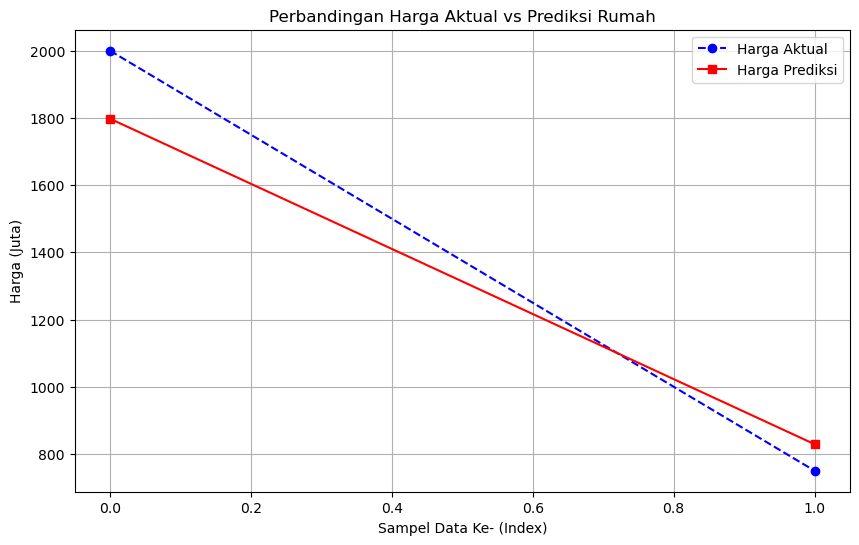

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

data_rumah = {
    'Luas_Tanah': [100, 150, np.nan, 200, 120, 300, 180, 90, 250, 110],
    'Jml_Kamar':  [2, 3, 3, 4, 2, 5, 3, 2, 4, np.nan],
    'Kondisi':    ['Baru', 'Lama', 'Baru', 'Baru', 'Lama', 'Baru', 'Lama', 'Lama', 'Baru', 'Lama'],
    'Harga_Juta': [500, 750, 800, 1000, 600, 2500, 850, 450, 2000, 550]
}
df_rumah = pd.DataFrame(data_rumah)

X = df_rumah.drop('Harga_Juta', axis=1)
y = df_rumah['Harga_Juta']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline_numerik = Pipeline(steps=[
    ('isi_kosong_num', SimpleImputer(strategy='median')),
    ('skala_num', StandardScaler())
])

pipeline_kategori = Pipeline(steps=[
    ('isi_kosong_cat', SimpleImputer(strategy='most_frequent')),
    ('encode_cat', OneHotEncoder(handle_unknown='ignore'))
])

kolom_num = ['Luas_Tanah', 'Jml_Kamar']
kolom_cat = ['Kondisi']

preprocessor_utama = ColumnTransformer(transformers=[
    ('proses_numerik', pipeline_numerik, kolom_num),
    ('proses_kategori', pipeline_kategori, kolom_cat)
])

model_akhir = Pipeline(steps=[
    ('semua_preprocessing', preprocessor_utama),
    ('algoritma_regresi', LinearRegression())
])

model_akhir.fit(X_train, y_train)

prediksi_harga = model_akhir.predict(X_test)

print("\n=== Hasil Studi Kasus ===")
print("Aktual :", y_test.values)
print("Prediksi:", np.round(prediksi_harga, 2))
print("MAE    : Rp", np.round(mean_absolute_error(y_test, prediksi_harga), 2), "Juta")
print("R2     :", np.round(r2_score(y_test, prediksi_harga), 2))

plt.figure(figsize=(10, 6))

plt.plot(range(len(y_test)), y_test.values, marker='o', label='Harga Aktual', color='blue', linestyle='--')
plt.plot(range(len(y_test)), prediksi_harga, marker='s', label='Harga Prediksi', color='red', linestyle='-')

plt.title('Perbandingan Harga Aktual vs Prediksi Rumah')
plt.xlabel('Sampel Data Ke- (Index)')
plt.ylabel('Harga (Juta)')
plt.legend()
plt.grid(True)



=== Hasil Studi Kasus Logistic Regression ===
Aktual   : [0 0 1 1 1 1]
Prediksi  : [0 0 1 0 1 1]
Akurasi   : 0.83

Classification Report:
               precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       1.00      0.75      0.86         4

    accuracy                           0.83         6
   macro avg       0.83      0.88      0.83         6
weighted avg       0.89      0.83      0.84         6



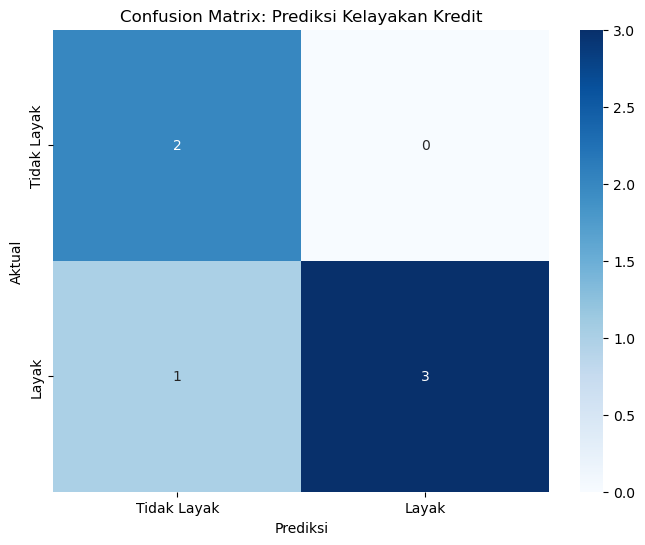

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

data_kredit = {
    'Pendapatan': [5, 10, np.nan, 15, 7, 25, 12, 4, 20, 8, 3, 22, 6, 18, 9, 28, 11, 5, 24, 7],
    'Usia':       [25, 30, 35, 45, 28, 50, 40, 22, 48, np.nan, 21, 55, 26, 42, 33, 58, 38, 24, 52, 29],
    'Status_Kerja': ['Tetap', 'Kontrak', 'Tetap', 'Tetap', 'Kontrak', 'Tetap', 'Kontrak', 'Kontrak', 'Tetap', 'Kontrak',
                    'Kontrak', 'Tetap', 'Kontrak', 'Tetap', 'Kontrak', 'Tetap', 'Kontrak', 'Kontrak', 'Tetap', 'Kontrak'],
    'Layak_Kredit': [0, 1, 1, 1, 0, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 1, 0]
}
df_kredit = pd.DataFrame(data_kredit)

X = df_kredit.drop('Layak_Kredit', axis=1)
y = df_kredit['Layak_Kredit']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

pipeline_numerik = Pipeline(steps=[
    ('isi_kosong_num', SimpleImputer(strategy='mean')),
    ('skala_num', StandardScaler())
])

pipeline_kategori = Pipeline(steps=[
    ('isi_kosong_cat', SimpleImputer(strategy='most_frequent')),
    ('encode_cat', OneHotEncoder(handle_unknown='ignore'))
])

kolom_num = ['Pendapatan', 'Usia']
kolom_cat = ['Status_Kerja']

preprocessor_utama = ColumnTransformer(transformers=[
    ('proses_numerik', pipeline_numerik, kolom_num),
    ('proses_kategori', pipeline_kategori, kolom_cat)
])

model_akhir = Pipeline(steps=[
    ('semua_preprocessing', preprocessor_utama),
    ('algoritma_klasifikasi', LogisticRegression())
])

model_akhir.fit(X_train, y_train)

prediksi_layak = model_akhir.predict(X_test)
probabilitas = model_akhir.predict_proba(X_test)[:, 1]

print("\n=== Hasil Studi Kasus Logistic Regression ===")
print("Aktual   :", y_test.values)
print("Prediksi  :", prediksi_layak)
print("Akurasi   :", np.round(accuracy_score(y_test, prediksi_layak), 2))
print("\nClassification Report:\n", classification_report(y_test, prediksi_layak))

plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, prediksi_layak)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Tidak Layak', 'Layak'], 
            yticklabels=['Tidak Layak', 'Layak'])
plt.title('Confusion Matrix: Prediksi Kelayakan Kredit')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.show()


ASSIGNMENT

=== 5 Data Teratas ===
   User ID Gender  Age  AnnualSalary  Purchased
0      385   Male   35         20000          0
1      681   Male   40         43500          0
2      353   Male   49         74000          0
3      895   Male   40        107500          1
4      661   Male   25         79000          0

=== Informasi Dataset ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   User ID       1000 non-null   int64 
 1   Gender        1000 non-null   object
 2   Age           1000 non-null   int64 
 3   AnnualSalary  1000 non-null   int64 
 4   Purchased     1000 non-null   int64 
dtypes: int64(4), object(1)
memory usage: 39.2+ KB
None

=== Cek Missing Values ===
User ID         0
Gender          0
Age             0
AnnualSalary    0
Purchased       0
dtype: int64

=== Statistik Deskriptif ===
           User ID          Age   AnnualSalary

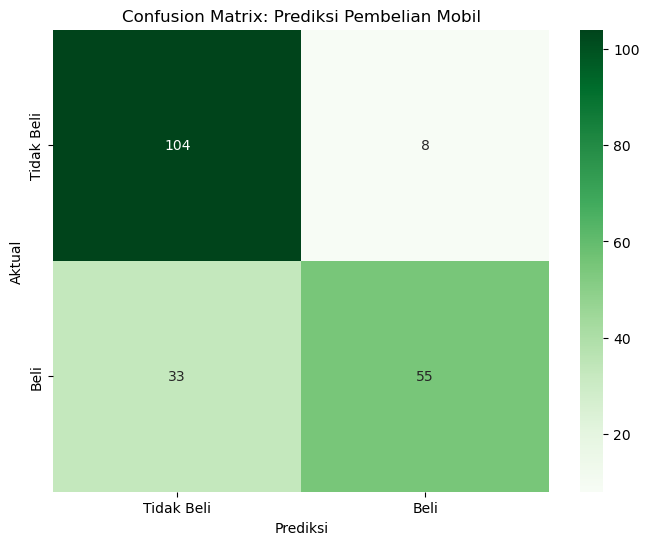

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# ==========================================================
# 1. Exploratory Data Analysis (EDA)
# ==========================================================
# Memuat dataset
df = pd.read_csv('car_data.csv')

print("=== 5 Data Teratas ===")
print(df.head())

print("\n=== Informasi Dataset ===")
print(df.info())

print("\n=== Cek Missing Values ===")
print(df.isnull().sum())

print("\n=== Statistik Deskriptif ===")
print(df.describe())

# ==========================================================
# 2. Data Preprocessing
# ==========================================================
# Hapus kolom User ID yang tidak relevan
X = df.drop(['User ID', 'Purchased'], axis=1)
y = df['Purchased']

# Mendefinisikan kolom numerik dan kategorikal
kolom_num = ['Age', 'AnnualSalary']
kolom_cat = ['Gender']

# Pipeline untuk masing-masing tipe data
pipeline_num = Pipeline(steps=[
    ('scaler', StandardScaler())
])

pipeline_cat = Pipeline(steps=[
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Menggabungkan preprocessing dalam ColumnTransformer
preprocessor = ColumnTransformer(transformers=[
    ('num', pipeline_num, kolom_num),
    ('cat', pipeline_cat, kolom_cat)
])

# ==========================================================
# 3. Modelling
# ==========================================================
# Membagi data menjadi train dan test set
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Membuat pipeline akhir (Preprocessing + Model)
model_pipeline = Pipeline(steps=[
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression())
])

# Training model
model_pipeline.fit(X_train, y_train)

# Prediksi
y_pred = model_pipeline.predict(X_test)

# ==========================================================
# 4. Evaluation
# ==========================================================
print("\n=== Evaluasi Model ===")
print(f"Accuracy Score: {accuracy_score(y_test, y_pred):.2f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

# Visualisasi Confusion Matrix
plt.figure(figsize=(8, 6))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Tidak Beli', 'Beli'],
            yticklabels=['Tidak Beli', 'Beli'])

plt.title('Confusion Matrix: Prediksi Pembelian Mobil')
plt.xlabel('Prediksi')
plt.ylabel('Aktual')

print("\nPenjelasan Confusion Matrix:")
print(f"- {cm[0,0]} nasabah diprediksi BENAR tidak membeli (True Negative).")
print(f"- {cm[1,1]} nasabah diprediksi BENAR akan membeli (True Positive).")
print(f"- {cm[0,1]} nasabah diprediksi membeli namun aslinya TIDAK (False Positive).")
print(f"- {cm[1,0]} nasabah diprediksi tidak membeli namun aslinya MEMBELI (False Negative).")

plt.show()
